У цьому домашньому завданні ми будемо працювати з набором даних Tips. Нижче інформація про нього.

**Про датасет:**

Tips - це датасет, який містить інформацію про рахунки та чайові в ресторані.

**Колонки датасету:**
- `total_bill` - загальна сума рахунку (долари)
- `tip` - розмір чайових (долари)
- `sex` - стать відвідувача (Male/Female)
- `smoker` - чи курить (Yes/No)
- `day` - день тижня (Thur/Fri/Sat/Sun)
- `time` - час відвідування (Lunch/Dinner)
- `size` - розмір групи (кількість людей)

**Джерело:** Оригінальні дані зібрані в одному з американських ресторанів у 1990-х роках. Скачати і переглянути набір даних можна тут: https://www.kaggle.com/datasets/sakshisatre/tips-dataset

А також ми вже вивантажили файл з даними і завантажили вам у Матеріали до цього модуля.




**1. Гістограма розподілу рахунків**
Завантажте датасет Tips (Чайові) з файла у матеріалах `tips.csv`.
Створіть гістограму для колонки `total_bill` з 20 bins.
Опціонально можна додати підписи осей ОХ, ОУ, а також назву графіку.

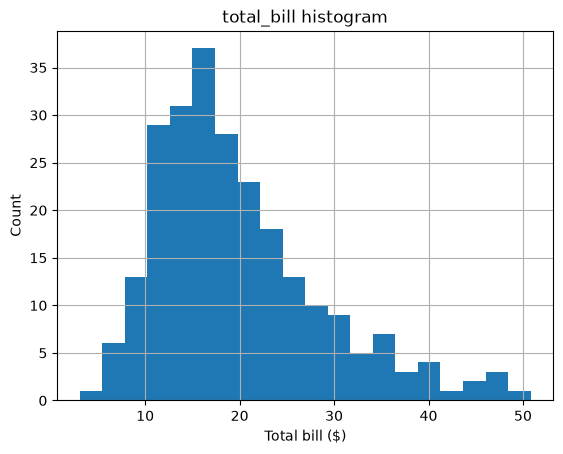

In [212]:
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Load the latest version
df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "sakshisatre/tips-dataset",
  'tip.csv',
  # Provide any additional arguments like 
  # sql_query or pandas_kwargs. See the 
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)

df['total_bill'].hist(bins=20)
plt.title('total_bill histogram')
plt.xlabel('Total bill ($)')
plt.ylabel('Count');

---

**2. Box plot чайових за днями тижня**

Створіть box plot, який показує розподіл чайових (`tip`) за днями тижня (`day`).
В який день навище медіанне значення чайоивх? Зелена горизонтальна лінія всередині кожного box-plot.


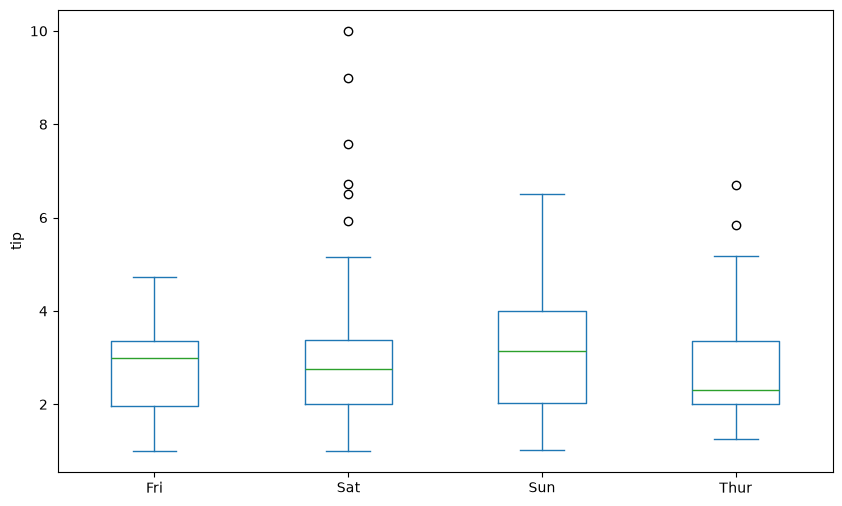

In [230]:
df.plot(kind='box', column='tip', by='day', figsize=(10,6))
plt.suptitle('')
plt.title('')
plt.ylabel('tip');
# Highest median tip: Sunday
# print(df.groupby('day')['tip'].median()) # Sun 3.15

---

**3. Scatter plot: рахунок vs чайові**

Створіть діаграму розсіювання для `total_bill` та `tip`.

<Axes: xlabel='total_bill', ylabel='tip'>

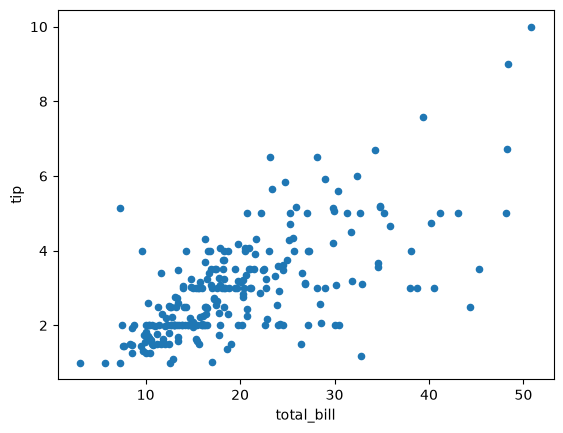

In [188]:
df.plot.scatter('total_bill', 'tip')

---

**4. Bar chart: середній рахунок за часом**

Створіть стовпчасту діаграму середнього рахунку за часом дня (`time`).

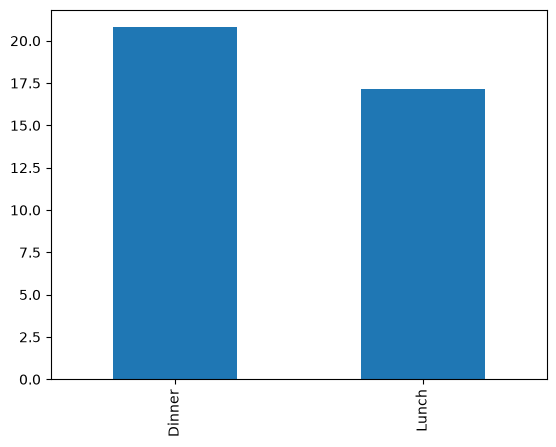

In [96]:
df['total_bill'].groupby(df['time']).mean().plot(kind='bar')
plt.xlabel('');

---

**5. Інтерактивна діаграма розсіювання**

Створіть з допомогою бібліотек Plotly інтерактивний scatter plot для `total_bill` vs `tip` з кольором за статтю (`sex`).


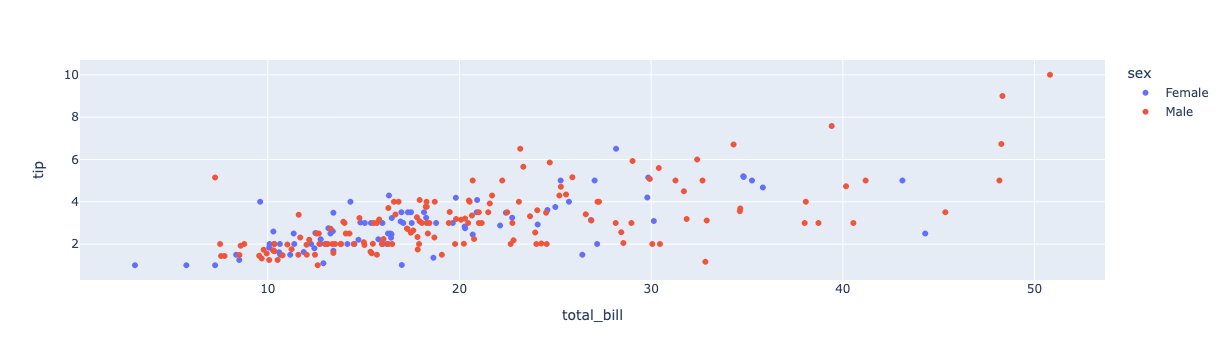

In [207]:
import plotly.express as px

fig = px.scatter(df, x='total_bill', y='tip', color='sex')
fig.show()

---

**6. Інтерактивний box plot: чайові за днями та статтю**

Створіть інтерактивний box plot для чайових за днями тижня з розбивкою за кольором по статі.

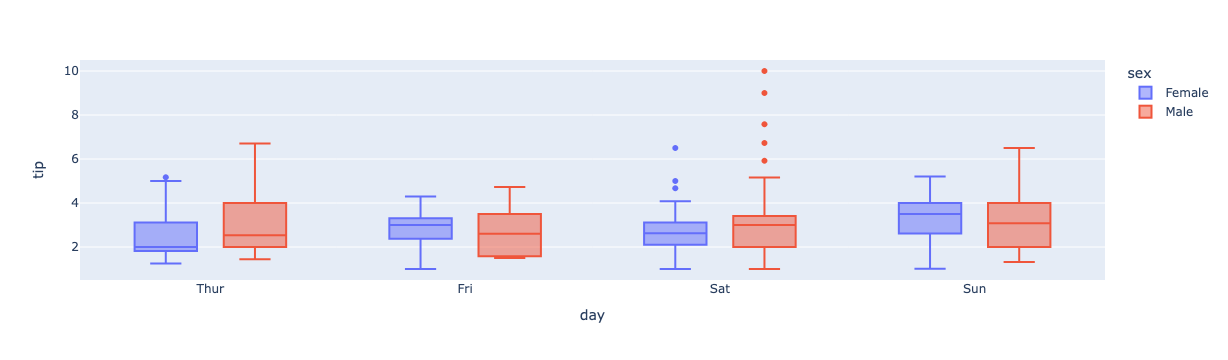

In [213]:
fig2 = px.box(df, x='day', y='tip', color='sex',
             category_orders={'day': ['Thur', 'Fri', 'Sat', 'Sun']})

fig2.show()